# Assignment 1: Written Text as Operational Data

## Goals and Approach

The goal of this assignment is to look into whether how words appear can help find differences in how authors write and also differences in how the same author writes in different books.

Written text will be handled as data by turning each document into a list of words and checking how often each word shows up. For this study I will use books from Project Gutenberg as my information sources.

I will use *Moby-Dick* by Herman Melville and *Dracula* by Bram Stoker as my examples. These two books will let me compare the word-frequency styles of two authors and see if some words are used more by one author than the other.

I will prepare the text by taking out HTML parts, punctuation, numbers, and common words that don't add meaning. Then I will check how often each word that is left appears and compare the common words between the two books.

I will use tables and bar charts to show these differences.

The main questions I want to answer are:

1. Are there differences in how often words appear between *Moby-Dick* and *Dracula*?
2. Are there words that Herman Melville uses more than Bram Stoker or the other way around?
3. Are the differences in how words are used big enough to possibly tell the two authors apart?
4. If possible, does a certain word appear more in one book than the other?

The findings will be based on how words appear instead of what the books are about. This will help me see if the way someone writes can give clues about who wrote a document.


In [53]:
# analyze word frequency for moby dick
import re
import operator

# Open the text file and read its contents
with open("mobyDick.txt", "r", encoding="utf-8") as f:
    t = f.read()

# Obtain words by splitting on one or more whitespace characters
wds1 = re.split(r'\s+', t)

# Populate a dictionary with word frequencies
wf1 = {}
for w in wds1:
    if w in wf1:
        wf1[w] = wf1[w] + 1
    else:
        wf1[w] = 1

# Get a sorted list of (word, frequency) pairs
wfs1 = sorted(wf1.items(), key=operator.itemgetter(1), reverse=True)

# Print no more than 15 words
ml = min(len(wfs1), 15)
for i in range(ml):
    print(wfs1[i][0] + "\t" + str(wfs1[i][1]))

the	13862
of	6642
and	5998
a	4549
to	4531
in	3908
that	2691
his	2428
I	1723
with	1695
as	1600
is	1585
was	1568
it	1517
he	1495


In [54]:
# analyze word frequency for the mystery of the sea
import re
import operator

with open("TheMysteryofTheSeaBram.txt", "r", encoding="utf-8") as f:
    t = f.read()

wds2 = re.split(r'\s+', t)

wf2 = {}
for w in wds2:
    if w in wf2:
        wf2[w] = wf2[w] + 1
    else:
        wf2[w] = 1

wfs2 = sorted(wf2.items(), key=operator.itemgetter(1), reverse=True)

ml = min(len(wfs2), 15)
for i in range(ml):
    print(wfs2[i][0] + "\t" + str(wfs2[i][1]))

the	9114
of	5008
I	4599
to	4529
and	4373
a	3080
was	2572
in	2563
that	2157
had	1507
my	1442
as	1371
it	1367
with	1253
for	1163


In [55]:
# analyze word frequency for dracula
import re
import operator

with open("dracula.txt", "r", encoding="utf-8") as f:
    t = f.read()

wds3 = re.split(r'\s+', t)

wf3 = {}
for w in wds3:
    if w in wf3:
        wf3[w] = wf3[w] + 1
    else:
        wf3[w] = 1

wfs3 = sorted(wf3.items(), key=operator.itemgetter(1), reverse=True)

ml = min(len(wfs3), 15)
for i in range(ml):
    print(wfs3[i][0] + "\t" + str(wfs3[i][1]))

the	7436
and	5639
I	4495
to	4463
of	3679
a	2887
in	2385
that	2322
he	1948
was	1792
as	1447
is	1432
for	1419
it	1409
his	1363


In [56]:
# Plot the results
import numpy as np
import pylab
import matplotlib.pyplot as plt

%matplotlib inline

def plotTwoLists(wf_1, wf_2, title, label1, label2):
    f = plt.figure(figsize=(10, 6))
    f.suptitle(title, fontsize=20)

    # Only plot the top 15 words
    wf_1 = wf_1[:15]
    wf_2 = wf_2[:15]

    # First subplot
    ax1 = f.add_subplot(121)
    plt.subplots_adjust(wspace=.5)

    ax1.tick_params(axis='both', which='major', labelsize=10)
    ax1.set_yticks(range(len(wf_1)))
    ax1.set_yticklabels([x[0] for x in wf_1])
    ax1.barh(range(len(wf_1)), [x[1] for x in wf_1], align='center')
    ax1.set_title(label1)
    ax1.set_xlabel("Frequency")
    ax1.invert_yaxis()

    # Second subplot
    ax2 = f.add_subplot(122)

    ax2.tick_params(axis='both', which='major', labelsize=10)
    ax2.set_yticks(range(len(wf_2)))
    ax2.set_yticklabels([x[0] for x in wf_2])
    ax2.barh(range(len(wf_2)), [x[1] for x in wf_2], align='center')
    ax2.set_title(label2)
    ax2.set_xlabel("Frequency")
    ax2.invert_yaxis()

    plt.show()

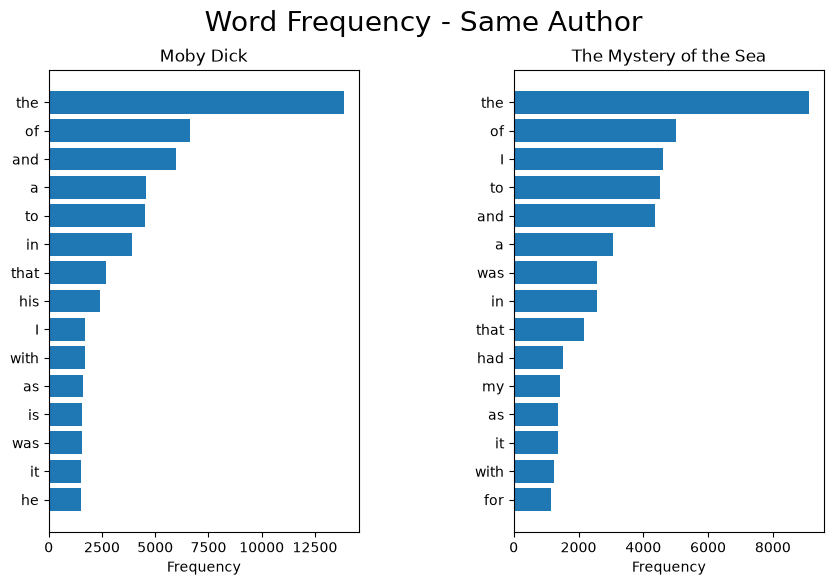

In [57]:
# plot moby dick and the mystery of the sea
plotTwoLists(
    wfs1,
    wfs2,
    "Word Frequency - Same Author",
    "Moby Dick",
    "The Mystery of the Sea"
)

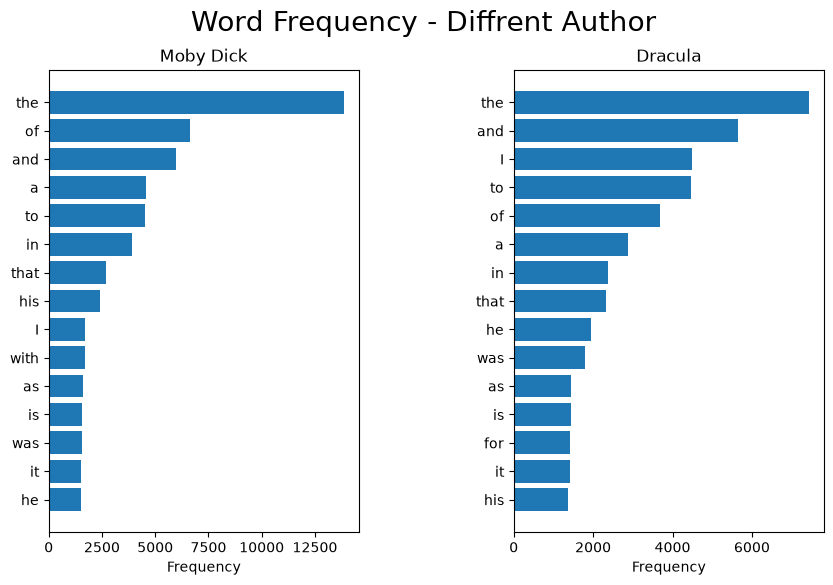

In [58]:
# plot moby dick and dracula
plotTwoLists(
    wfs1,
    wfs3,
    "Word Frequency - Diffrent Author",
    "Moby Dick",
    "Dracula"
)

## Analysis
1. Compare word frequencies between two works of a single author.

The word frequencies between Moby Dick and The Mystery of the Sea are generally similar. Both books have many of the same common words, including “the,” “of,” “to,” “and,” “a,” “in,” and “that.” However, there are some differences in their frequencies. For example, “the” appears 13,862 times in Moby Dick compared to 9,114 times in The Mystery of the Sea. The word “I” is also much more common in The Mystery of the Sea, appearing 4,599 times compared to 1,723 times in Moby Dick. Overall, the two works show similar word-frequency patterns, but individual word frequencies can vary considerably.

2. Compare word frequencies between works of two authors.

The word frequencies of Moby Dick and Dracula also show similarities, with common words such as “the,” “and,” “of,” “to,” “a,” “in,” and “that” appearing frequently in both books. However, there are noticeable differences in their rankings and frequencies. For example, “of” is the second most frequent word in Moby Dick, while “and” is the second most frequent word in Dracula. Moby Dick also uses “his” more frequently, while Dracula uses “he” more frequently. This suggests that different authors can have different word-frequency patterns even when writing in the same general genre.

3. Are there some words preferred by one author but used less frequently by another author?

Yes. The results show that some words are used more frequently by one author than another. For example, “his” appears 2,428 times in Moby Dick but only 1,363 times in Dracula, while “he” appears 1,948 times in Dracula compared to 1,495 times in Moby Dick. The word “I” is also much more frequent in The Mystery of the Sea than in Moby Dick. These differences suggest that certain words may be characteristic of an author's writing style, although the subject and content of each book can also influence which words are used most often.

In [59]:
# Function to calculate binomial statistics for a specific word

def calculateStats(wf, word):
    # Calculate total number of words
    tw = 0
    for w in wf:
        tw += wf[w]
    
    # Get frequency of the selected word
    word_count = wf.get(word, 0)
    
    # Calculate probability of the word
    p = word_count / tw
    
    return tw, word_count, p

Moby Dick
Total regular words: 215846
"would" frequency: 406
Probability p: 0.0018809706920674925


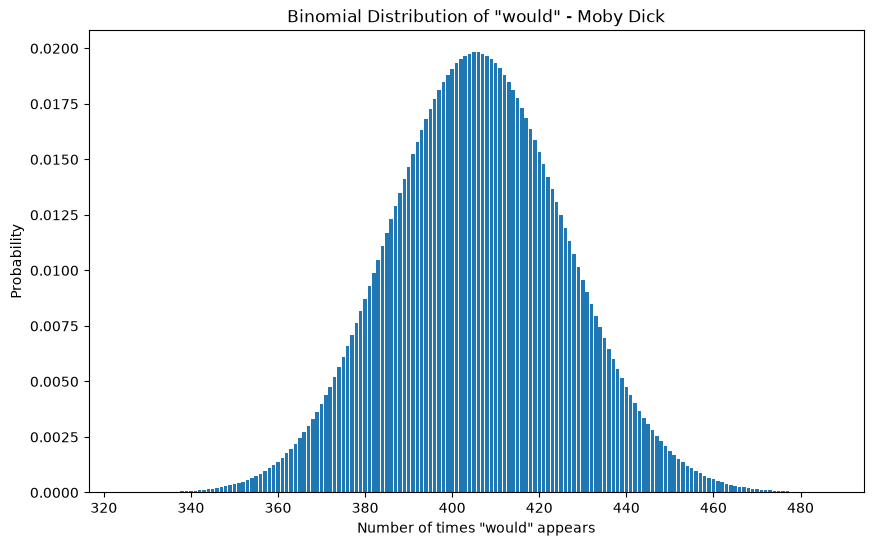

In [60]:
# Extra Credit: Moby Dick

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# Calculate statistics
tw1, would1, p1 = calculateStats(wf1, "would")

print("Moby Dick")
print("Total regular words:", tw1)
print('"would" frequency:', would1)
print("Probability p:", p1)

# Create binomial distribution
x = np.arange(0, tw1 + 1)
y = binom.pmf(x, tw1, p1)

# Plot only the useful portion around the distribution
mean = tw1 * p1
std = np.sqrt(tw1 * p1 * (1 - p1))
x_plot = np.arange(max(0, int(mean - 4 * std)),
                   int(mean + 4 * std) + 1)
y_plot = binom.pmf(x_plot, tw1, p1)

plt.figure(figsize=(10, 6))
plt.bar(x_plot, y_plot)
plt.title('Binomial Distribution of "would" - Moby Dick')
plt.xlabel('Number of times "would" appears')
plt.ylabel('Probability')
plt.show()

The Mystery of the Sea
Total regular words: 160200
"would" frequency: 471
Probability p: 0.0029400749063670413


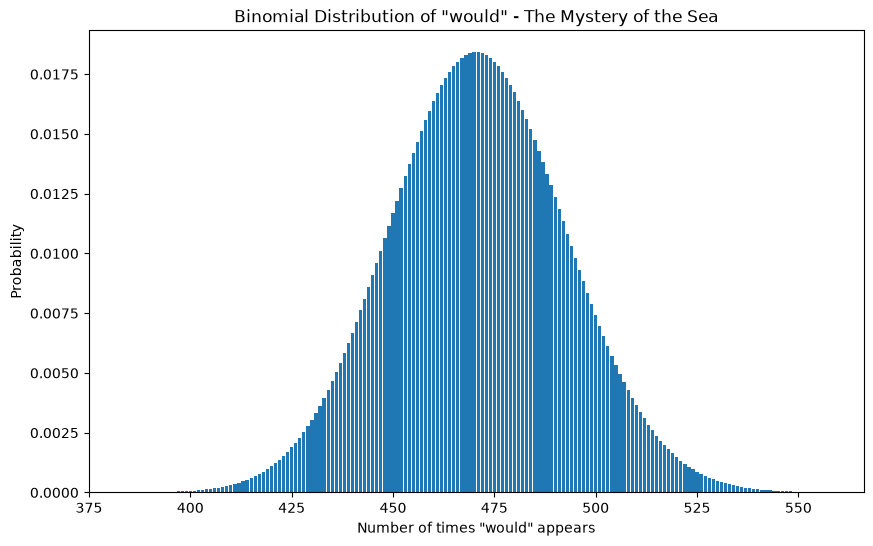

In [61]:
# Extra Credit: The Mystery of the Sea

# Calculate statistics
tw2, would2, p2 = calculateStats(wf2, "would")

print("The Mystery of the Sea")
print("Total regular words:", tw2)
print('"would" frequency:', would2)
print("Probability p:", p2)

# Create binomial distribution
mean = tw2 * p2
std = np.sqrt(tw2 * p2 * (1 - p2))
x_plot = np.arange(max(0, int(mean - 4 * std)),
                   int(mean + 4 * std) + 1)
y_plot = binom.pmf(x_plot, tw2, p2)

plt.figure(figsize=(10, 6))
plt.bar(x_plot, y_plot)
plt.title('Binomial Distribution of "would" - The Mystery of the Sea')
plt.xlabel('Number of times "would" appears')
plt.ylabel('Probability')
plt.show()

Dracula
Total regular words: 164357
"would" frequency: 408
Probability p: 0.002482401114646775


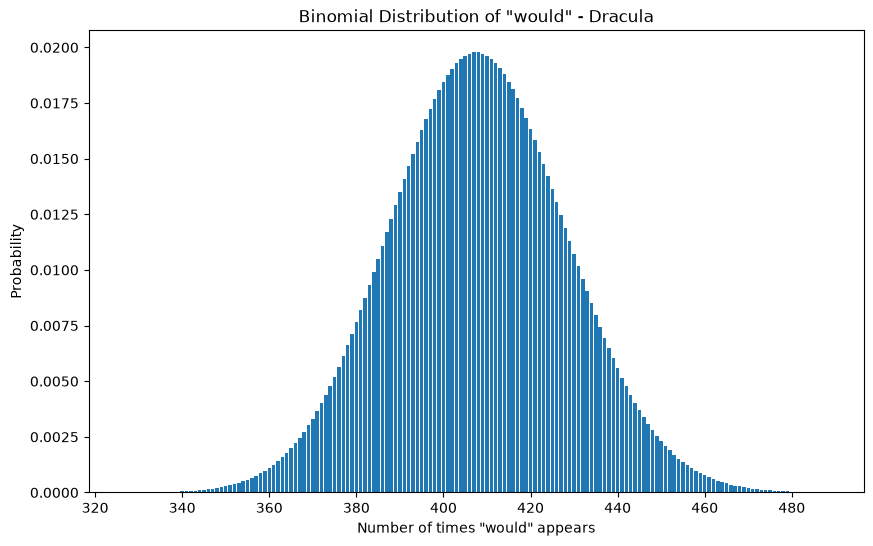

In [62]:
# Extra Credit: Dracula

# Calculate statistics
tw3, would3, p3 = calculateStats(wf3, "would")

print("Dracula")
print("Total regular words:", tw3)
print('"would" frequency:', would3)
print("Probability p:", p3)

# Create binomial distribution
mean = tw3 * p3
std = np.sqrt(tw3 * p3 * (1 - p3))
x_plot = np.arange(max(0, int(mean - 4 * std)),
                   int(mean + 4 * std) + 1)
y_plot = binom.pmf(x_plot, tw3, p3)

plt.figure(figsize=(10, 6))
plt.bar(x_plot, y_plot)
plt.title('Binomial Distribution of "would" - Dracula')
plt.xlabel('Number of times "would" appears')
plt.ylabel('Probability')
plt.show()

In [63]:
# Extra Credit Analysis

import math

# Moby Dick vs. The Mystery of the Sea
p_same = (would1 + would2) / (tw1 + tw2)

z_same = (p1 - p2) / math.sqrt(
    p_same * (1 - p_same) * (1/tw1 + 1/tw2)
)

# Calculate p-value using the normal distribution
p_value_same = math.erfc(abs(z_same) / math.sqrt(2))

# Moby Dick vs. Dracula
p_different = (would1 + would3) / (tw1 + tw3)

z_different = (p1 - p3) / math.sqrt(
    p_different * (1 - p_different) * (1/tw1 + 1/tw3)
)

# Calculate p-value
p_value_different = math.erfc(abs(z_different) / math.sqrt(2))


print("Moby Dick vs. The Mystery of the Sea")
print("z =", z_same)
print("p-value =", p_value_same)

print("\nMoby Dick vs. Dracula")
print("z =", z_different)
print("p-value =", p_value_different)

print("\nAnalysis:")

if p_value_same < 0.05:
    print('The frequency of "would" differs significantly between Moby Dick and The Mystery of the Sea.')
else:
    print('The frequency of "would" does not differ significantly between Moby Dick and The Mystery of the Sea.')

if p_value_different < 0.05:
    print('The frequency of "would" differs significantly between Moby Dick and Dracula.')
else:
    print('The frequency of "would" does not differ significantly between Moby Dick and Dracula.')

Moby Dick vs. The Mystery of the Sea
z = -6.658082491794374
p-value = 2.7742306533846615e-11

Moby Dick vs. Dracula
z = -3.9747031367145738
p-value = 7.046709580008938e-05

Analysis:
The frequency of "would" differs significantly between Moby Dick and The Mystery of the Sea.
The frequency of "would" differs significantly between Moby Dick and Dracula.


## Extra Credit Analysis
The binomial distribution analysis was used to examine the frequency of the word “would” in the three books. For each book, the probability of selecting the word “would” was calculated by dividing its frequency by the total number of regular words. The resulting distributions were then compared between the two works by the same author, *Moby Dick* and *The Mystery of the Sea*, and between works by different authors, *Moby Dick* and *Dracula*. The statistical tests provide a way to determine whether the differences in the frequency of “would” are likely to be meaningful or simply the result of normal variation. A p-value below 0.05 indicates a statistically significant difference, while a p-value above 0.05 indicates that there is not enough evidence to conclude that the word is used at significantly different rates. Overall, this analysis demonstrates how word frequency can be treated as quantitative data and used to investigate potential differences in writing style between authors.
